# E004 — Device & Merchant Behavioral Feature Engineering (CatBoost GPU)

**Research question:** Do device sharing, merchant activity, and card–merchant familiarity help detect bank-card fraud beyond the **original 14 features**?

**Control benchmark:** E001 three-fold time CV, mean ROC AUC **0.87424**. Independent earlier candidates: E002-B **0.89328** (spending) and E003-A **0.90917** (velocity). E004 does **not** include E002/E003 features; those groups will be combined in E006.

**Experimental controls:** same three expanding-window folds, same categorical preparation, CatBoost hyperparameters, NVIDIA GPU, early stopping, and metric (ROC AUC). A fresh CatBoost model is fitted for each fold and feature set.

**Feature availability policy:** The competition permits unlabeled, full-dataset aggregates from `train + test`. This is **transductive** feature engineering: features may reflect future *unlabeled* transactions. We do **not** use `is_fraud` to build any feature. Such full-history counts would **not** be available unchanged in a real-time payment system; that system would require past-only aggregates.

**Experiments (5 × 3 folds = 15 GPU fits):**

| Experiment | Original features plus | Question |
|---|---|---|
| E001-repeat | Nothing | Can we reproduce our baseline? |
| E004-A | Device behavior | Are devices shared between multiple cards? |
| E004-B | Merchant behavior | Does merchant popularity/typical spending help? |
| E004-C | Card–merchant familiarity | Has the card used this merchant often? |
| E004-D | All three E004 groups | Do these groups complement one another? |

**Professor checkpoint:** A device shared by multiple cards is not necessarily fraudulent (e.g., a family device). We test predictive association rather than treating sharing as a fraud label.

## 1 — Load the project data

Use the original CSV files and their correct timestamp formats. `train.csv` contains fraud labels; `test.csv` does not. We only pass **unlabeled input columns** into the feature builder.

The file finder works when you start Jupyter either from the repository root or from its `notebooks/` directory.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

working_dir = Path.cwd()
possible_data_dirs = [working_dir / "data", working_dir.parent / "data"]
data_dir = next(
    (folder for folder in possible_data_dirs
     if (folder / "train.csv").exists() and (folder / "test.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Expected data/train.csv and data/test.csv in your repository.")

project_root = data_dir.parent
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")

train_raw["timestamp"] = pd.to_datetime(
    train_raw["timestamp"], format="%Y-%m-%d %H:%M:%S"
)
test_raw["timestamp"] = pd.to_datetime(
    test_raw["timestamp"], format="%m/%d/%Y %H:%M"
)
train_raw = train_raw.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert "is_fraud" in train_raw.columns
assert "is_fraud" not in test_raw.columns
assert train_raw["transaction_id"].is_unique
assert test_raw["transaction_id"].is_unique
assert train_raw["timestamp"].max() < test_raw["timestamp"].min()
print("Project root:", project_root)
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
print("Train dates:", train_raw["timestamp"].min(), "to", train_raw["timestamp"].max())
print("Test dates: ", test_raw["timestamp"].min(), "to", test_raw["timestamp"].max())

Project root: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Train: (60197, 20) | Test: (39803, 19)
Train dates: 2026-01-01 00:07:15 to 2026-02-05 23:59:19
Test dates:  2026-02-06 00:07:00 to 2026-03-02 00:36:00


## 2 — Define the feature groups

### Device features (E004-A)

| Feature | Definition | Why it might matter |
|---|---|---|
| `device_txn_count` | Number of all transactions made on this real device | Overall device activity |
| `device_unique_cards` | Different cards observed on this device | Multiple cards using a single device |
| `card_unique_devices` | Different real devices observed for this card | Customer/device diversity |
| `card_device_txn_count` | Transactions for this exact card–device pair | Familiar versus unfamiliar card/device combination |

**Critical rule:** Blank `device_id` represents *no device*, **not one giant shared device**. Therefore device-level counts are zero for in-store/recurring transactions with missing IDs. `card_unique_devices` can still be positive for those rows, because it describes the card's full online history.

### Merchant features (E004-B)

| Feature | Definition |
|---|---|
| `merchant_txn_count` | Total transactions at merchant |
| `merchant_unique_cards` | Number of distinct cards seen at merchant |
| `merchant_amount_median` | Median transaction amount at merchant |

### Card–merchant familiarity features (E004-C)

| Feature | Definition |
|---|---|
| `card_merchant_txn_count` | Number of transactions involving this exact card–merchant pair |
| `card_unique_merchants` | Number of different merchants visited by this card |

All counts are **unlabeled full-history aggregates**, and thus include the row itself and may include later transactions. This is allowed for the competition; it is different from E003's strictly past-only velocity features.

In [2]:
DEVICE_FEATURES = [
    "device_txn_count",
    "device_unique_cards",
    "card_unique_devices",
    "card_device_txn_count",
]
MERCHANT_FEATURES = [
    "merchant_txn_count",
    "merchant_unique_cards",
    "merchant_amount_median",
]
FAMILIARITY_FEATURES = [
    "card_merchant_txn_count",
    "card_unique_merchants",
]
ENGINEERED_FEATURES = DEVICE_FEATURES + MERCHANT_FEATURES + FAMILIARITY_FEATURES


def build_device_merchant_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Return transaction_id + label-free device/merchant aggregate features.

    Only uses: transaction_id, card_id, device_id, merchant_id, amount.
    Group statistics include all supplied unlabeled rows, including the current row.
    """
    required_columns = [
        "transaction_id", "card_id", "device_id", "merchant_id", "amount"
    ]
    if not set(required_columns).issubset(transaction_rows.columns):
        raise ValueError(f"Missing required fields: {set(required_columns) - set(transaction_rows.columns)}")

    events = transaction_rows[required_columns].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique for one-to-one joining")
    if events[["card_id", "merchant_id", "amount"]].isna().any().any():
        raise ValueError("card_id, merchant_id, and amount must not be missing")

    # Blank device IDs mean "no device", not a common device shared by all rows.
    has_real_device = events["device_id"].fillna("").astype(str).str.strip().ne("")
    online_devices = events.loc[has_real_device, ["card_id", "device_id"]].copy()

    device_stats = (
        online_devices.groupby("device_id", as_index=False)
        .agg(device_txn_count=("card_id", "size"),
             device_unique_cards=("card_id", "nunique"))
    )
    card_device_diversity = (
        online_devices.groupby("card_id", as_index=False)
        .agg(card_unique_devices=("device_id", "nunique"))
    )
    card_device_frequency = (
        online_devices.groupby(["card_id", "device_id"], as_index=False)
        .size().rename(columns={"size": "card_device_txn_count"})
    )

    merchant_stats = (
        events.groupby("merchant_id", as_index=False)
        .agg(merchant_txn_count=("transaction_id", "size"),
             merchant_unique_cards=("card_id", "nunique"),
             merchant_amount_median=("amount", "median"))
    )
    card_merchant_frequency = (
        events.groupby(["card_id", "merchant_id"], as_index=False)
        .size().rename(columns={"size": "card_merchant_txn_count"})
    )
    card_merchant_diversity = (
        events.groupby("card_id", as_index=False)
        .agg(card_unique_merchants=("merchant_id", "nunique"))
    )

    features = events[["transaction_id", "card_id", "merchant_id", "device_id"]].copy()
    features = features.merge(device_stats, on="device_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(card_device_diversity, on="card_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(
        card_device_frequency, on=["card_id", "device_id"],
        how="left", validate="many_to_one", sort=False
    )
    features = features.merge(merchant_stats, on="merchant_id", how="left", validate="many_to_one", sort=False)
    features = features.merge(
        card_merchant_frequency, on=["card_id", "merchant_id"],
        how="left", validate="many_to_one", sort=False
    )
    features = features.merge(
        card_merchant_diversity, on="card_id", how="left", validate="many_to_one", sort=False
    )

    # The first three device-specific counts are 0 if this transaction has no real device;
    # card_unique_devices is 0 only for a card that has never used a real device.
    for feature in ["device_txn_count", "device_unique_cards",
                    "card_unique_devices", "card_device_txn_count"]:
        features[feature] = features[feature].fillna(0).astype("int32")
    for feature in ["merchant_txn_count", "merchant_unique_cards",
                    "card_merchant_txn_count", "card_unique_merchants"]:
        features[feature] = features[feature].astype("int32")

    assert len(features) == len(events)
    assert features["transaction_id"].equals(events["transaction_id"])
    assert features[ENGINEERED_FEATURES].notna().all().all()
    return features[["transaction_id"] + ENGINEERED_FEATURES]


# Union only the original unlabeled columns needed by the feature builder.
needed = ["transaction_id", "card_id", "device_id", "merchant_id", "amount"]
all_unlabeled_transactions = pd.concat(
    [train_raw[needed], test_raw[needed]], ignore_index=True
)
assert all_unlabeled_transactions["transaction_id"].is_unique

feature_table = build_device_merchant_features(all_unlabeled_transactions)
train_features = train_raw.merge(
    feature_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)
test_features = test_raw.merge(
    feature_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)

assert len(train_features) == len(train_raw)
assert len(test_features) == len(test_raw)
assert train_features["transaction_id"].equals(train_raw["transaction_id"])
assert test_features["transaction_id"].equals(test_raw["transaction_id"])
assert train_features[ENGINEERED_FEATURES].notna().all().all()
assert test_features[ENGINEERED_FEATURES].notna().all().all()

print("Engineered", len(ENGINEERED_FEATURES), "new features.")
print("Train shape:", train_features.shape, "| Test shape:", test_features.shape)
display(train_features[["card_id", "device_id", "merchant_id"] + ENGINEERED_FEATURES].head())

Engineered 9 new features.
Train shape: (60197, 29) | Test shape: (39803, 28)


,card_id,device_id,merchant_id,device_txn_count,device_unique_cards,card_unique_devices,card_device_txn_count,merchant_txn_count,merchant_unique_cards,merchant_amount_median,card_merchant_txn_count,card_unique_merchants
0,C03949,NaN,M00042,0,0,5,0,77,56,52.40,4,21
1,C02996,NaN,M00532,0,0,1,0,41,31,133.65,3,12
2,C06754,NaN,M00800,0,0,1,0,37,28,105.56,1,12
3,C03321,D007559,M01947,1,1,14,1,69,48,17.86,5,24
4,C00958,D001759,M00380,22,3,1,1,44,36,29.71,1,2


## 3 — Unit tests and leakage safeguards

Before training, test the feature calculations on a hand-checkable example. Also verify the special handling of missing `device_id` values in the real dataset.

**Why the tests matter:** A naive `groupby("device_id")` that fills all blanks with `"Unknown"` would incorrectly make tens of thousands of offline transactions appear to share one device.

In [3]:
toy = pd.DataFrame({
    "transaction_id": ["t1", "t2", "t3", "t4", "t5"],
    "card_id": ["A", "A", "B", "A", "C"],
    "device_id": ["D1", "D1", "D1", None, "D2"],
    "merchant_id": ["M1", "M1", "M1", "M2", "M2"],
    "amount": [20., 40., 90., 10., 70.],
})
toy_features = build_device_merchant_features(toy).set_index("transaction_id")
assert toy_features.loc["t1", "device_txn_count"] == 3
assert toy_features.loc["t1", "device_unique_cards"] == 2
assert toy_features.loc["t1", "card_device_txn_count"] == 2
assert toy_features.loc["t4", "device_txn_count"] == 0
assert toy_features.loc["t4", "device_unique_cards"] == 0
assert toy_features.loc["t4", "card_device_txn_count"] == 0
assert toy_features.loc["t4", "card_unique_devices"] == 1
assert toy_features.loc["t1", "merchant_txn_count"] == 3
assert toy_features.loc["t1", "merchant_unique_cards"] == 2
assert toy_features.loc["t1", "merchant_amount_median"] == 40.0
assert toy_features.loc["t1", "card_merchant_txn_count"] == 2
assert toy_features.loc["t1", "card_unique_merchants"] == 2

no_device = train_features["device_id"].isna()
assert (train_features.loc[
    no_device,
    ["device_txn_count", "device_unique_cards", "card_device_txn_count"]
] == 0).all().all()
assert (train_features.loc[~no_device, "device_txn_count"] >= 1).all()
assert (train_features.loc[~no_device, "device_unique_cards"] >= 1).all()
assert (train_features["merchant_txn_count"] >= 1).all()
assert (train_features["card_merchant_txn_count"] >= 1).all()
assert (train_features["card_unique_merchants"] >= 1).all()

print("PASS — Hand-calculated aggregation test")
print("PASS — Missing device IDs do not become one shared device")
print("PASS — All transaction keys preserved and count features are valid")
display(toy.merge(toy_features.reset_index(), on="transaction_id"))

PASS — Hand-calculated aggregation test
PASS — Missing device IDs do not become one shared device
PASS — All transaction keys preserved and count features are valid


,transaction_id,card_id,device_id,merchant_id,amount,device_txn_count,device_unique_cards,card_unique_devices,card_device_txn_count,merchant_txn_count,merchant_unique_cards,merchant_amount_median,card_merchant_txn_count,card_unique_merchants
0,t1,A,D1,M1,20.0,3,2,1,2,3,2,40.0,2,2
1,t2,A,D1,M1,40.0,3,2,1,2,3,2,40.0,2,2
2,t3,B,D1,M1,90.0,3,2,1,1,3,2,40.0,1,1
3,t4,A,NaN,M2,10.0,0,0,1,0,2,2,40.0,1,2
4,t5,C,D2,M2,70.0,1,1,1,1,2,2,40.0,1,1


## 4 — Explore the engineered features **before** model training

Look for distributions, outliers, and missingness. We may use `is_fraud` to **describe** labeled training rows here, but never to **create** a feature.

**Questions:** How often are devices shared by at least two cards? How common are repeat card–merchant relationships? Do high-sharing devices show a higher *observed* fraud rate? Remember that observational patterns do not prove fraud or causation.

,feature,min,median,p95,max
0,device_txn_count,0.00,0.00,14.00,60.00
1,device_unique_cards,0.00,0.00,3.00,8.00
2,card_unique_devices,0.00,5.00,17.00,43.00
3,card_device_txn_count,0.00,0.00,12.00,60.00
4,merchant_txn_count,21.00,52.00,76.00,117.00
5,merchant_unique_cards,17.00,37.00,50.00,97.00
6,merchant_amount_median,5.51,20.98,89.88,155.32
7,card_merchant_txn_count,1.00,1.00,6.00,20.00
8,card_unique_merchants,1.00,15.00,43.00,83.00


Rows without device (in_store/recurring): 31403
Online rows on a device used by >=2 cards: 47.30%
Transactions where the card has visited this merchant >=2 times: 43.76%
Observed labeled fraud rates (descriptive only):


,transactions,frauds,fraud_rate
device_sharing_group,,,
No device,31403,347,0.011050
1 card,15174,211,0.013905
2 cards,9702,170,0.017522
3+ cards,3918,71,0.018121


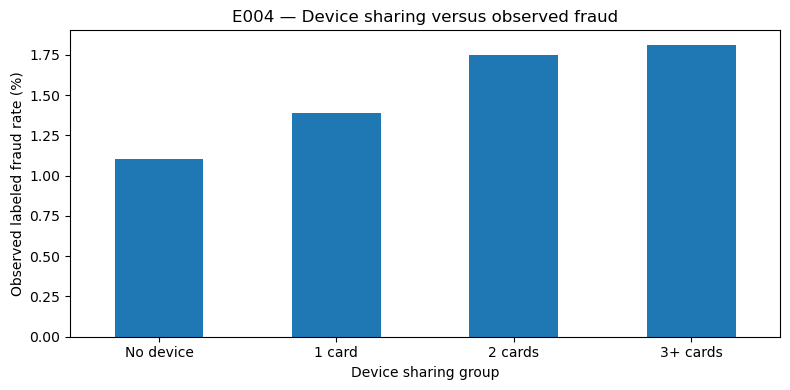

In [4]:
feature_overview = pd.DataFrame({
    "feature": ENGINEERED_FEATURES,
    "min": [train_features[c].min() for c in ENGINEERED_FEATURES],
    "median": [train_features[c].median() for c in ENGINEERED_FEATURES],
    "p95": [train_features[c].quantile(.95) for c in ENGINEERED_FEATURES],
    "max": [train_features[c].max() for c in ENGINEERED_FEATURES],
})
display(feature_overview.round(2))

online_rows = train_features["device_id"].notna()
print("Rows without device (in_store/recurring):", int((~online_rows).sum()))
print("Online rows on a device used by >=2 cards:",
      f"{(train_features.loc[online_rows, 'device_unique_cards'] >= 2).mean():.2%}")
print("Transactions where the card has visited this merchant >=2 times:",
      f"{(train_features['card_merchant_txn_count'] >= 2).mean():.2%}")

# Exploratory labels: group fraud rates AFTER engineering, never feed rates into CatBoost.
sharing_level = pd.cut(
    train_features["device_unique_cards"], bins=[-1, 0, 1, 2, float("inf")],
    labels=["No device", "1 card", "2 cards", "3+ cards"]
)
observed = (
    train_features.assign(device_sharing_group=sharing_level)
    .groupby("device_sharing_group", observed=True)
    .agg(transactions=("is_fraud", "size"),
         frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"))
)
print("Observed labeled fraud rates (descriptive only):")
display(observed)

fig, ax = plt.subplots(figsize=(8, 4))
observed["fraud_rate"].mul(100).plot.bar(ax=ax)
ax.set(ylabel="Observed labeled fraud rate (%)", xlabel="Device sharing group",
       title="E004 — Device sharing versus observed fraud")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5 — Controlled feature sets and the original chronological folds

We retain the original E001 feature columns and preprocessing. The dates below **match E001/E002/E003** exactly:

| Fold | Train uses timestamps before | Validation window (inclusive start, exclusive end) |
|---|---|---|
| 1 | Jan 19 | Jan 19–24, 2026 |
| 2 | Jan 25 | Jan 25–30, 2026 |
| 3 | Jan 31 | Jan 31–Feb 5, 2026 |

Both train and validation include legitimate and fraudulent transactions. We do not shuffle or stratify because the competition's unseen test is later in time.

In [5]:
excluded_columns = {
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
}
original_features = [
    column for column in train_raw.columns if column not in excluded_columns
]
assert len(original_features) == 14, original_features

feature_sets = {
    "E001-repeat": original_features,
    "E004-A": original_features + DEVICE_FEATURES,
    "E004-B": original_features + MERCHANT_FEATURES,
    "E004-C": original_features + FAMILIARITY_FEATURES,
    "E004-D": original_features + ENGINEERED_FEATURES,
}

cat_features = train_raw[original_features].select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]

for experiment_name, columns in feature_sets.items():
    assert len(columns) == len(set(columns))
    assert set(columns).issubset(train_features.columns)
    print(f"{experiment_name:12s}: {len(columns)} features")
print("Categorical predictors:", cat_features)

fold_checks = []
for fold_number, (start, end) in enumerate(time_folds, start=1):
    start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
    train_mask = train_features["timestamp"] < start_date
    valid_mask = (
        (train_features["timestamp"] >= start_date)
        & (train_features["timestamp"] < end_date)
    )
    y_train_fold = train_features.loc[train_mask, "is_fraud"]
    y_valid_fold = train_features.loc[valid_mask, "is_fraud"]
    assert y_train_fold.nunique() == 2
    assert y_valid_fold.nunique() == 2
    assert train_features.loc[train_mask, "timestamp"].max() < start_date
    fold_checks.append({
        "fold": fold_number,
        "train_rows": len(y_train_fold),
        "train_frauds": int(y_train_fold.sum()),
        "valid_rows": len(y_valid_fold),
        "valid_frauds": int(y_valid_fold.sum()),
        "valid_start": start,
        "valid_end_exclusive": end,
    })
display(pd.DataFrame(fold_checks))

E001-repeat : 14 features
E004-A      : 18 features
E004-B      : 17 features
E004-C      : 16 features
E004-D      : 23 features
Categorical predictors: ['card_id', 'customer_home_country', 'merchant_id', 'merchant_category', 'merchant_country', 'channel', 'device_id', 'ip_country']


,fold,train_rows,train_frauds,valid_rows,valid_frauds,valid_start,valid_end_exclusive
0,1,29618,409,10336,140,2026-01-19,2026-01-25
1,2,39954,549,10263,94,2026-01-25,2026-01-31
2,3,50217,643,9980,156,2026-01-31,2026-02-06


## 6 — Train all E004 experiments on NVIDIA GPU

This section performs **15 separate CatBoost fits** (5 feature sets × 3 time-based folds). Each fold has a fresh model. Model settings match E001/E003:

- `iterations=600`, `depth=6`, `learning_rate=0.05`, `l2_leaf_reg=3`
- `loss_function="Logloss"`, `eval_metric="AUC"`, `early_stopping_rounds=70`
- `task_type="GPU"`, `devices="0"`, `random_seed=42`
- Categorical missing values are filled with `"__MISSING__"`; `card_present` becomes integer.

An informational CatBoost message such as *“AUC is/are not implemented for GPU”* refers to AUC calculation frequency, **not** whether your model is using GPU for training. ROC AUC is computed separately using scikit-learn after every fit.

**Important:** Early stopping selects the best iteration based on the same validation window; these are development/model-selection estimates, not an untouched final evaluation.

In [6]:
EXPERIMENTS_TO_RUN = ["E001-repeat", "E004-A", "E004-B", "E004-C", "E004-D"]

model_parameters = dict(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    task_type="GPU",
    devices="0",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

results = []
importance_records = []

for experiment_name in EXPERIMENTS_TO_RUN:
    selected_columns = feature_sets[experiment_name]
    print(f"\n===== {experiment_name}: {len(selected_columns)} features =====")

    for fold_number, (start, end) in enumerate(time_folds, start=1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        train_mask = train_features["timestamp"] < start_date
        valid_mask = (
            (train_features["timestamp"] >= start_date)
            & (train_features["timestamp"] < end_date)
        )

        X_fold_train = train_features.loc[train_mask, selected_columns].copy()
        X_fold_valid = train_features.loc[valid_mask, selected_columns].copy()
        y_fold_train = train_features.loc[train_mask, "is_fraud"]
        y_fold_valid = train_features.loc[valid_mask, "is_fraud"]

        # Same E001/E002/E003 preprocessing.
        for frame in (X_fold_train, X_fold_valid):
            frame["card_present"] = frame["card_present"].astype("int8")
            frame[cat_features] = frame[cat_features].fillna("__MISSING__").astype(str)

        assert X_fold_train.columns.tolist() == X_fold_valid.columns.tolist()
        assert X_fold_train[cat_features].notna().all().all()
        assert X_fold_train.select_dtypes(include=["number"]).notna().all().all()

        model = CatBoostClassifier(**model_parameters)
        started_at = perf_counter()
        model.fit(
            X_fold_train, y_fold_train,
            cat_features=cat_features,
            eval_set=(X_fold_valid, y_fold_valid),
            early_stopping_rounds=70,
            use_best_model=True,
        )
        train_seconds = perf_counter() - started_at
        probabilities = model.predict_proba(X_fold_valid)[:, 1]
        fold_auc = roc_auc_score(y_fold_valid, probabilities)

        results.append({
            "experiment_id": experiment_name,
            "fold": fold_number,
            "train_rows": len(X_fold_train),
            "valid_rows": len(X_fold_valid),
            "valid_frauds": int(y_fold_valid.sum()),
            "roc_auc": fold_auc,
            "best_iteration": model.best_iteration_,
            "train_seconds": round(train_seconds, 2),
        })

        for feature_name, importance in zip(
            selected_columns, model.get_feature_importance()
        ):
            importance_records.append({
                "experiment_id": experiment_name,
                "fold": fold_number,
                "feature": feature_name,
                "importance": float(importance),
            })

        print(
            f"Fold {fold_number}: ROC AUC={fold_auc:.5f}, "
            f"best_iteration={model.best_iteration_}, "
            f"train_seconds={train_seconds:.1f}"
        )

results_df = pd.DataFrame(results)
importance_all_folds = pd.DataFrame(importance_records)
display(results_df)


===== E001-repeat: 14 features =====


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: ROC AUC=0.88680, best_iteration=90, train_seconds=9.3


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: ROC AUC=0.83746, best_iteration=16, train_seconds=5.1


Default metric period is 5 because AUC is/are not implemented for GPU


... (22 outputs left out)

Fold 2: ROC AUC=0.87506, best_iteration=10, train_seconds=5.0


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: ROC AUC=0.87439, best_iteration=96, train_seconds=5.0


,experiment_id,fold,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration,train_seconds
0,E001-repeat,1,29618,10336,140,0.886802,90,9.31
1,E001-repeat,2,39954,10263,94,0.837461,16,5.10
2,E001-repeat,3,50217,9980,156,0.898440,14,2.63
3,E004-A,1,29618,10336,140,0.894471,239,17.61
4,E004-A,2,39954,10263,94,0.854044,321,21.94
5,E004-A,3,50217,9980,156,0.896292,11,2.64
6,E004-B,1,29618,10336,140,0.883425,308,21.46
7,E004-B,2,39954,10263,94,0.854754,68,8.12
8,E004-B,3,50217,9980,156,0.862493,81,4.54
9,E004-C,1,29618,10336,140,0.897793,270,19.12


## 7 — Compare mean AUC and **paired fold** improvements

The **main decision criterion** is mean cross-validation ROC AUC, but always inspect improvements fold by fold. A higher mean with a large drop in one period is less convincing than consistent gains.

We compare against **the E001 baseline rerun inside this notebook**, rather than relying only on results from a prior notebook. E002-B (0.89328) and E003-A (0.90917) are external reference lines, **not** results to average with E004.

,experiment_id,mean_roc_auc,std_roc_auc,min_fold_auc,max_fold_auc,mean_best_iteration,delta_vs_e001
0,E001-repeat,0.87423,0.03237,0.83746,0.89844,40.00000,0.00000
1,E004-A,0.88160,0.02388,0.85404,0.89629,190.33333,0.00737
2,E004-B,0.86689,0.01483,0.85475,0.88342,152.33333,-0.00734
3,E004-C,0.88374,0.02925,0.85012,0.90330,100.33333,0.00950
4,E004-D,0.87915,0.00768,0.87439,0.88801,123.66667,0.00492


experiment_id,E001-repeat,E004-A,E004-B,E004-C,E004-D
fold,,,,,
1,0.88680,0.89447,0.88342,0.89779,0.88801
2,0.83746,0.85404,0.85475,0.85012,0.87506
3,0.89844,0.89629,0.86249,0.90330,0.87439


ROC AUC difference vs the baseline in each identical time fold:


experiment_id,E001-repeat,E004-A,E004-B,E004-C,E004-D
fold,,,,,
1,0.0,0.00767,-0.00338,0.01099,0.00121
2,0.0,0.01658,0.01729,0.01266,0.03760
3,0.0,-0.00215,-0.03595,0.00486,-0.02405


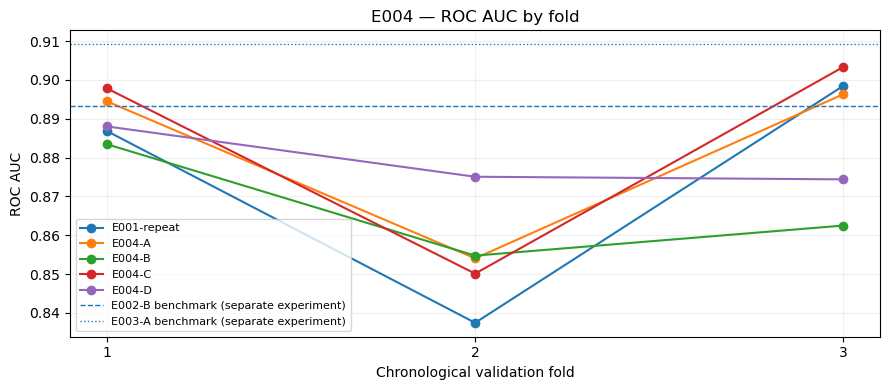

In [7]:
summary_df = (
    results_df.groupby("experiment_id", sort=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        min_fold_auc=("roc_auc", "min"),
        max_fold_auc=("roc_auc", "max"),
        mean_best_iteration=("best_iteration", "mean"),
    )
    .reset_index()
)

baseline_auc = float(
    summary_df.loc[
        summary_df["experiment_id"] == "E001-repeat", "mean_roc_auc"
    ].iloc[0]
)
summary_df["delta_vs_e001"] = summary_df["mean_roc_auc"] - baseline_auc

display(summary_df.round(5))
fold_auc_table = results_df.pivot(
    index="fold", columns="experiment_id", values="roc_auc"
)
display(fold_auc_table.round(5))

paired_differences = fold_auc_table.subtract(fold_auc_table["E001-repeat"], axis=0)
print("ROC AUC difference vs the baseline in each identical time fold:")
display(paired_differences.round(5))

fig, ax = plt.subplots(figsize=(9, 4))
for experiment_name in fold_auc_table.columns:
    ax.plot(
        fold_auc_table.index, fold_auc_table[experiment_name],
        marker="o", label=experiment_name
    )
ax.axhline(0.89328, linestyle="--", linewidth=1,
           label="E002-B benchmark (separate experiment)")
ax.axhline(0.90917, linestyle=":", linewidth=1,
           label="E003-A benchmark (separate experiment)")
ax.set(
    xlabel="Chronological validation fold", ylabel="ROC AUC",
    title="E004 — ROC AUC by fold", xticks=[1, 2, 3]
)
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

## 8 — Feature importance across all folds

Feature importance describes which columns CatBoost used in the fitted model. It does **not** tell us whether a feature is causal, whether a higher value always increases fraud probability, or whether removing it improves validation ROC AUC.

Do not make feature-selection decisions based only on one fold's importance or a zero score.

In [8]:
for experiment_name in ["E004-A", "E004-B", "E004-C", "E004-D"]:
    subset = importance_all_folds.loc[
        importance_all_folds["experiment_id"] == experiment_name
    ]
    importance_summary = (
        subset.groupby("feature", as_index=False)
        .agg(
            mean_importance=("importance", "mean"),
            min_importance=("importance", "min"),
            max_importance=("importance", "max"),
        )
        .sort_values("mean_importance", ascending=False)
    )
    print("\n", experiment_name, "— mean feature importance across folds")
    display(importance_summary.head(24).round(3))


 E004-A — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
1,amount,27.214,15.526,33.359
15,merchant_category,21.668,13.054,36.103
17,merchant_id,14.353,12.031,15.940
14,is_foreign_merchant,10.156,5.902,16.855
3,card_id,5.478,0.000,8.515
0,account_age_days,3.317,1.539,4.455
2,card_device_txn_count,3.091,2.517,4.167
6,channel,2.691,2.285,3.064
16,merchant_country,1.979,1.438,2.594
13,is_foreign_ip,1.703,1.507,1.996



 E004-B — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
1,amount,33.413,30.793,36.816
2,card_id,11.830,9.190,14.625
16,merchant_unique_cards,11.417,9.210,13.039
12,merchant_category,10.720,7.833,13.552
10,is_foreign_merchant,7.804,4.919,9.272
11,merchant_amount_median,5.072,4.959,5.145
9,is_foreign_ip,3.864,2.336,5.814
4,channel,3.245,2.473,4.272
15,merchant_txn_count,3.191,1.714,5.072
0,account_age_days,2.335,0.970,3.103



 E004-C — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
13,merchant_category,28.051,14.297,36.035
1,amount,25.802,11.678,35.378
15,merchant_id,12.181,11.396,12.589
12,is_foreign_merchant,9.132,5.025,13.841
3,card_merchant_txn_count,8.206,7.777,8.645
6,channel,4.320,2.249,7.524
2,card_id,3.027,0.000,7.387
11,is_foreign_ip,2.112,0.638,3.097
14,merchant_country,1.627,0.607,2.339
0,account_age_days,1.423,0.382,2.841



 E004-D — mean feature importance across folds


,feature,mean_importance,min_importance,max_importance
1,amount,24.927,10.673,36.810
22,merchant_unique_cards,22.753,10.169,44.148
18,merchant_category,10.672,8.873,14.145
16,is_foreign_merchant,6.843,2.610,8.981
3,card_id,6.048,0.000,10.279
4,card_merchant_txn_count,5.053,4.898,5.276
17,merchant_amount_median,4.102,1.276,5.831
21,merchant_txn_count,2.920,1.600,4.526
15,is_foreign_ip,2.513,2.002,3.115
2,card_device_txn_count,2.299,1.843,2.925


## 9 — Save reproducible results

Save three compact CSV files inside your repository's `experiments/` directory:

- `E004_cv_results.csv` — every fold and training run
- `E004_summary.csv` — mean AUC, variability, and comparison against E001
- `E004_feature_importance.csv` — every feature's importance for each fold

Only commit the summary/results after reviewing them. The notebook itself should also be committed to Git.

In [9]:
experiments_dir = project_root / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

fold_results_path = experiments_dir / "E004_cv_results.csv"
summary_path = experiments_dir / "E004_summary.csv"
importance_path = experiments_dir / "E004_feature_importance.csv"

results_df.to_csv(fold_results_path, index=False)
summary_df.to_csv(summary_path, index=False)
importance_all_folds.to_csv(importance_path, index=False)

print("Saved:", fold_results_path)
print("Saved:", summary_path)
print("Saved:", importance_path)

Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E004_cv_results.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E004_summary.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E004_feature_importance.csv


## 10 — Interpretation and decision (complete **after** running)

Fill in your actual results:

| Experiment | Mean ROC AUC | Δ vs E001 | Fold consistency | Decision |
|---|---:|---:|---|---|
| E001-repeat | _pending_ | 0 | Reference | Control |
| E004-A (device) | _pending_ | _pending_ | _pending_ | Keep / investigate |
| E004-B (merchant) | _pending_ | _pending_ | _pending_ | Keep / investigate |
| E004-C (familiarity) | _pending_ | _pending_ | _pending_ | Keep / investigate |
| E004-D (all E004) | _pending_ | _pending_ | _pending_ | Keep / investigate |

**Questions for your experiment notes:**

1. Which feature group achieves the largest **mean** ROC AUC gain over 0.87424?
2. Does that group improve all three chronological folds?
3. Does E004-D beat the strongest *individual* E004 feature group?
4. If `device_unique_cards` is important, does it help beyond raw `device_id`?
5. Should the group be a candidate for combination with E002-B and E003-A in E006?

**Research limitation:** Repeated feature selection on three validation windows can overfit our choice to those windows. The reported estimates use fold-specific early stopping and full-history *unlabeled* aggregates, so they are development scores, not untouched final test estimates. Preserve a later labeled holdout or use a limited final leaderboard check once our pipeline is fixed.

**Next planned experiment:** E005 — Geography and location-change features. Then E006 — Cross-group feature combinations.